# Information
This script investigate the previously fit baseline regressor, which proved that host age is surprisingly well predictable from microbial composition. In particular, the goal is to refine the understanding of the regressor by looking at the features which drive the association between composition and age the most

# 0. Setup
load required packages
specify paths

In [11]:
import pandas as pd
import numpy as np
import qiime2 as q2
import matplotlib.pyplot as plt
import scipy.stats as st
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import seaborn as sns


%matplotlib inline

In [12]:
data_dir="../../data"
featuretable_dir="../../output/02_taxonomicclassification"
output_dir="../../output/05_ML"

# 1. Load model
Since this script analyzes the ML model and its data in detail, the model is here bulit using python instead of qiime. While qiime served as a good, quick tool to fit models and compare them, thorough analyses are better performed on python-build models

In [13]:
ft = q2.Artifact.load(f"{featuretable_dir}/feature-table.qza").view(pd.DataFrame) 
meta = pd.read_csv(f"{data_dir}/metadata.tsv", sep="\t", index_col="sample-id").loc[ft.index]
y = meta["host_age"]
groups = meta["host_id"]

In [14]:
rf = RandomForestRegressor(n_estimators=500, random_state=22, n_jobs=-1) # fit regressor
pred = cross_val_predict(rf, ft, y, cv=GroupKFold(5), groups=groups) # use group-level cross-validation to avoid bias from multiple measurements of one child
y_true = y
y_pred = pd.Series(pred, index=y.index)

In [ ]:
lr = st.linregress(y_true, y_pred)
metrics = pd.Series({
    "MAE": mean_absolute_error(y_true, y_pred),
    "MSE": mean_squared_error(y_true, y_pred),
    "r": lr.rvalue, "R2": r2_score(y_true, y_pred),
    "p-value": lr.pvalue, "SE": lr.stderr,
    "slope": lr.slope, "intercept": lr.intercept,
}, name="value").to_frame()
display(metrics)


fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(y_true, y_pred, alpha=0.6)
xs = np.array([y_true.min(), y_true.max()])
ax.plot(xs, lr.slope * xs + lr.intercept, color="C1", label="")
ax.plot(xs, xs, "k--", label="")
ax.set(xlabel="True host age", ylabel="Predicted host age")
ax.legend()
plt.show()

# 2. Feature importance

In [9]:
tax = q2.Artifact.load(f"{featuretable_dir}/../02_taxonomicclassification/taxonomy-table.qza").view(pd.DataFrame)

# 3. Top features species level

In [10]:
rel = ft.div(ft.sum(axis=1), axis=0)
top5 = top.index[:5]
fig, axes = plt.subplots(1, 5, figsize=(20, 3.5), sharex=True)
for ax, f in zip(axes, top5):
    d = pd.DataFrame({"age": y, "abund": rel[f], "id": groups})
    for _, g in d.groupby("id"):
        ax.plot(g["age"], g["abund"], color="grey", alpha=0.3, lw=0.8)
    ax.plot(*d.groupby(pd.cut(d["age"], 8), observed=True).agg(age=("age", "mean"), abund=("abund", "mean")).values.T, color="C3", lw=2)
    ax.set_title(top.loc[f, "Taxon"].split(";")[-1].strip(), fontsize=9)
    ax.set_xlabel("host age")
plt.show()

NameError: name 'top' is not defined

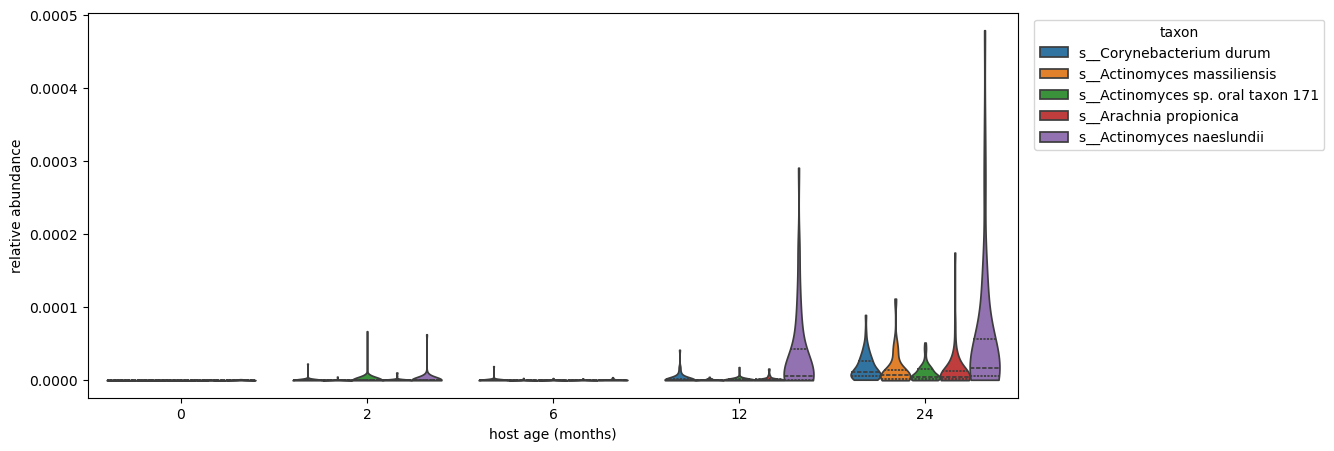

In [12]:
rel = ft.div(ft.sum(axis=1), axis=0)
top5 = top.index[:5]
labels = {f: top.loc[f, "Taxon"].split(";")[-1].strip() for f in top5}

long = (rel[top5].rename(columns=labels)
        .assign(timepoint=y.astype(int).values)
        .melt(id_vars="timepoint", var_name="taxon", value_name="rel_abundance"))

fig, ax = plt.subplots(figsize=(12, 5))
sns.violinplot(data=long, x="timepoint", y="rel_abundance", hue="taxon",
               order=[0, 2, 6, 12, 24], cut=0, inner="quartile",
               density_norm="width", ax=ax)
ax.set(xlabel="host age (months)", ylabel="relative abundance")
ax.legend(title="taxon", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.show()

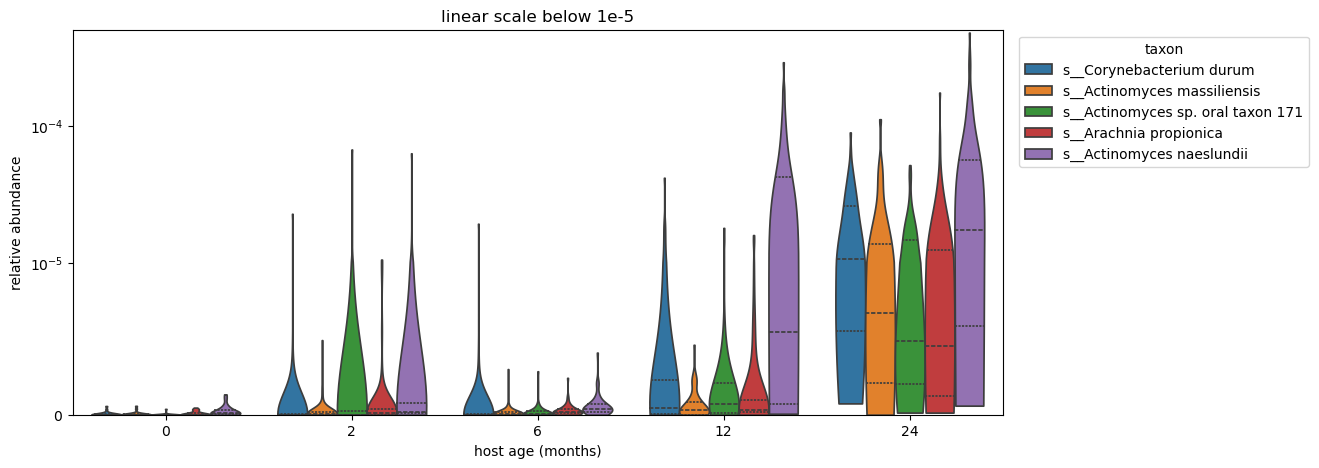

In [22]:
rel = ft.div(ft.sum(axis=1), axis=0)
top5 = top.index[:5]
labels = {f: top.loc[f, "Taxon"].split(";")[-1].strip() for f in top5}

long = (rel[top5].rename(columns=labels)
        .assign(timepoint=y.astype(int).values)
        .melt(id_vars="timepoint", var_name="taxon", value_name="rel_abundance"))

fig, ax = plt.subplots(figsize=(12, 5))
sns.violinplot(data=long, x="timepoint", y="rel_abundance", hue="taxon",
               order=[0, 2, 6, 12, 24], cut=0, inner="quartile",
               density_norm="width", ax=ax)
ax.set(xlabel="host age (months)", ylabel="relative abundance")
ax.legend(title="taxon", bbox_to_anchor=(1.01, 1), loc="upper left")
ax.set_yscale("symlog", linthresh=1e-5)   # linear below 0.1%, log above
ax.set_ylim(bottom=0)
plt.title("linear scale below 1e-5")
plt.show()

## 4. top features (genus level)

In [12]:
rf.fit(ft, y)
imp = pd.DataFrame({"importance": rf.feature_importances_}, index=ft.columns).join(tax["Taxon"])
top = imp.sort_values("importance", ascending=False).head(20)
top

# map each species feature to its genus (from the g__ part of the lineage)
tax = q2.Artifact.load(f"{featuretable_dir}/taxonomy-table.qza").view(pd.DataFrame)
genus = (tax["Taxon"].str.extract(r"g__([^;]+)")[0]
         .str.strip().reindex(ft.columns).fillna("unassigned_genus"))

# sum counts of all species within each genus -> samples x genera
ft_genus = ft.T.groupby(genus).sum().T

# same model and importance code as before, on ft_genus
rf = RandomForestRegressor(n_estimators=500, random_state=22, n_jobs=-1)
rf.fit(ft_genus, y)
imp_genus = pd.Series(rf.feature_importances_, index=ft_genus.columns).sort_values(ascending=False)
print(imp_genus.head(5))

0
Arachnia            0.219816
Anaerobutyricum     0.127688
Faecalibacterium    0.113087
Lautropia           0.078431
Saccharibacillus    0.032064
dtype: float64


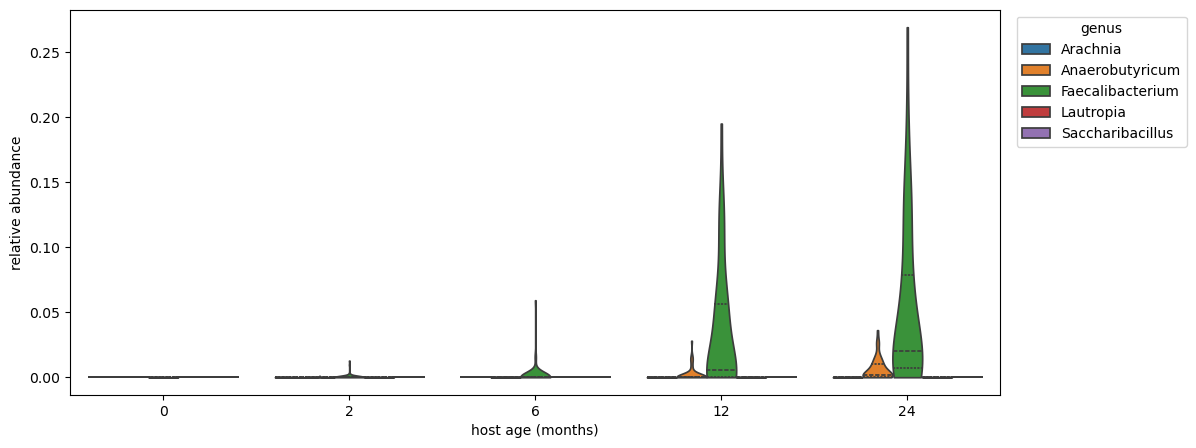

In [14]:
rel_genus = ft_genus.div(ft_genus.sum(axis=1), axis=0)
top4 = imp_genus.drop("unassigned_genus", errors="ignore").index[:5]

long = (rel_genus[top4]
        .assign(timepoint=y.astype(int).values)
        .melt(id_vars="timepoint", var_name="genus", value_name="rel_abundance"))

fig, ax = plt.subplots(figsize=(12, 5))
sns.violinplot(data=long, x="timepoint", y="rel_abundance", hue="genus",
               order=[0, 2, 6, 12, 24], cut=0, inner="quartile",
               density_norm="width", ax=ax)
ax.set(xlabel="host age (months)", ylabel="relative abundance")
ax.legend(title="genus", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.show()

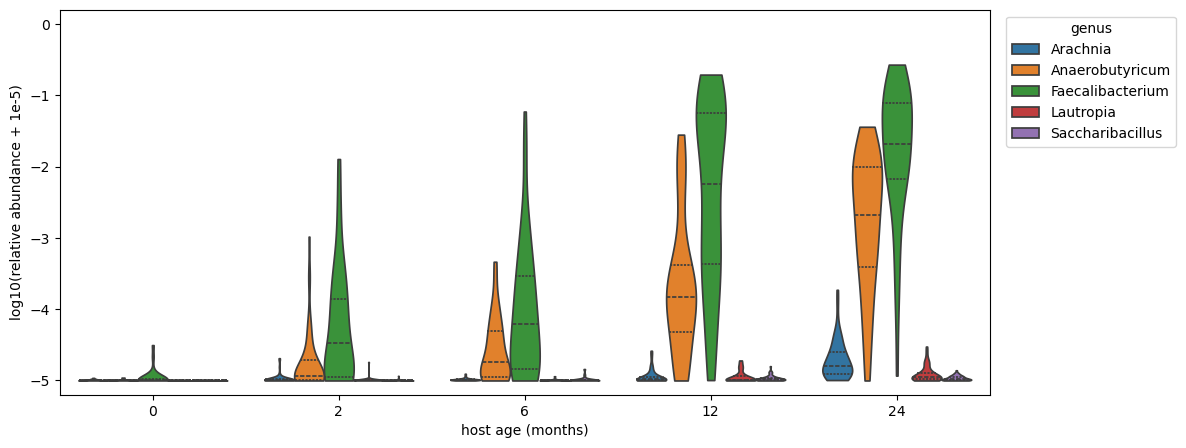

In [17]:
rel_genus = ft_genus.div(ft_genus.sum(axis=1), axis=0)
top4 = imp_genus.drop("unassigned_genus", errors="ignore").index[:5]

pseudo = 1e-5   # keep identical to the other plot

long = (rel_genus[top4]
        .assign(timepoint=y.astype(int).values)
        .melt(id_vars="timepoint", var_name="genus", value_name="rel_abundance"))
long["log_abund"] = np.log10(long["rel_abundance"] + pseudo)

fig, ax = plt.subplots(figsize=(12, 5))
sns.violinplot(data=long, x="timepoint", y="log_abund", hue="genus",
               order=[0, 2, 6, 12, 24], cut=0, inner="quartile",
               density_norm="width", ax=ax)
ax.set(xlabel="host age (months)", ylabel="log10(relative abundance + 1e-5)")
ax.set_ylim(-5.2, 0.2)   # same limits as the other plot
ax.legend(title="genus", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.show()

# 5. Biologically expected top features (compared to birth)

Bifidobacterium       234
Veillonella           225
Blautia               229
Mediterraneibacter    231
Bacteroides           231
Faecalibacterium      218
Enterococcus          231
dtype: int64


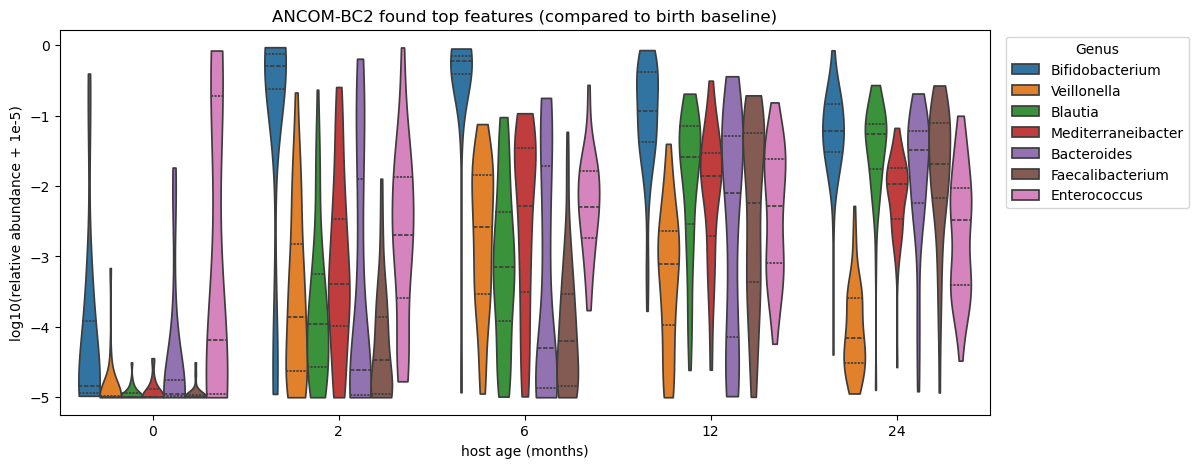

In [15]:
genera = ["Bifidobacterium", "Veillonella", "Blautia", "Mediterraneibacter", "Bacteroides", "Faecalibacterium", "Enterococcus"]

# sum all features whose taxonomy contains the genus (g__ prefix avoids partial matches)
rel = ft.div(ft.sum(axis=1), axis=0)
genus_abund = pd.DataFrame({
    g: rel.loc[:, rel.columns.isin(tax.index[tax["Taxon"].str.contains(rf"g__{g}\b", na=False)])].sum(axis=1)
    for g in genera
})
print((genus_abund > 0).sum())   # sanity check: samples with the genus present (all columns should be > 0)

long = (genus_abund
        .assign(timepoint=y.astype(int).values)
        .melt(id_vars="timepoint", var_name="genus", value_name="rel_abundance"))
long["log_abund"] = np.log10(long["rel_abundance"] + 1e-5)

fig, ax = plt.subplots(figsize=(12, 5))
sns.violinplot(data=long, x="timepoint", y="log_abund", hue="genus",
               order=[0, 2, 6, 12, 24], cut=0, inner="quartile",
               density_norm="width", ax=ax)
ax.set(xlabel="host age (months)", ylabel="log10(relative abundance + 1e-5)")
ax.legend(title="Genus", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.title("ANCOM-BC2 found top features (compared to birth baseline)")
plt.savefig(f"{output_dir}/ANCOM-BC2_top_features.png", dpi=300, bbox_inches="tight")
plt.show()

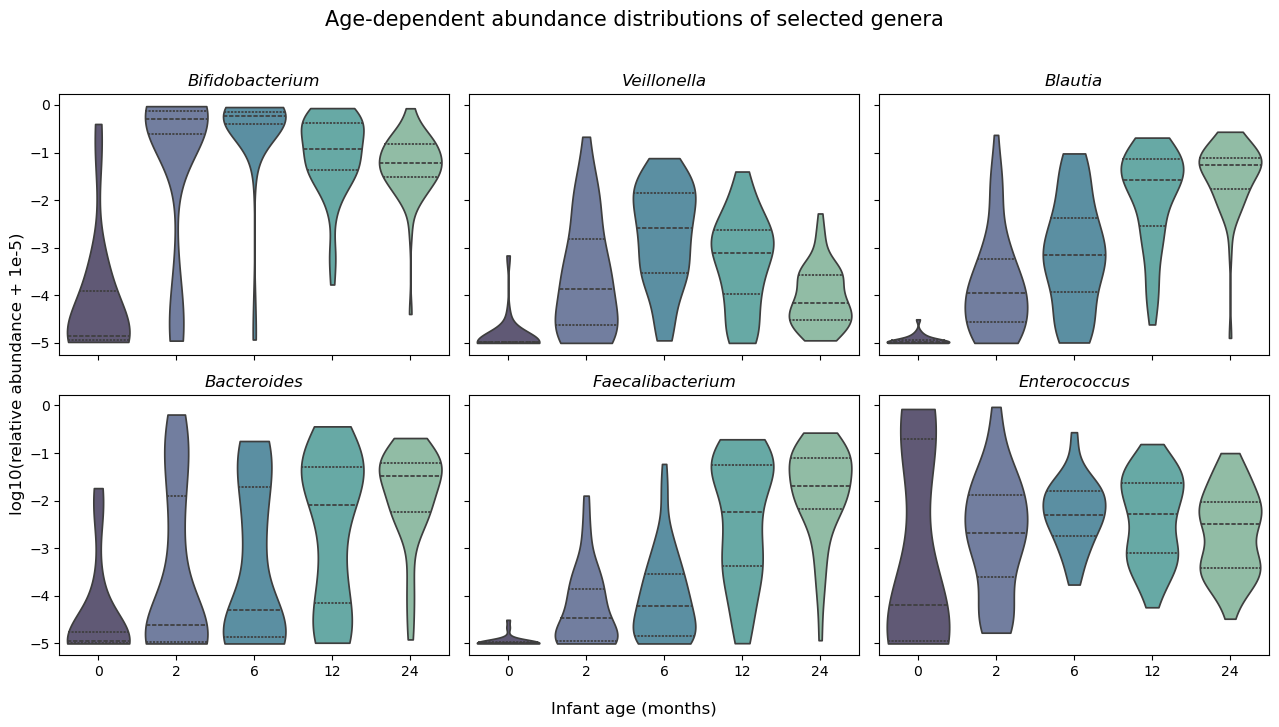

In [25]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Six selected genera
genera = [
    "Bifidobacterium",
    "Veillonella",
    "Blautia",
    "Bacteroides",
    "Faecalibacterium",
    "Enterococcus"
]

# Calculate relative abundance
rel = ft.div(ft.sum(axis=1), axis=0)

genus_abund = pd.DataFrame({
    g: rel.loc[
        :,
        rel.columns.isin(
            tax.index[
                tax["Taxon"].str.contains(
                    rf"g__{g}\b", na=False
                )
            ]
        )
    ].sum(axis=1)
    for g in genera
})

# Convert to long format
long = (
    genus_abund
    .assign(timepoint=y.astype(int).values)
    .melt(
        id_vars="timepoint",
        var_name="genus",
        value_name="rel_abundance"
    )
)

long["log_abund"] = np.log10(
    long["rel_abundance"] + 1e-5
)

# Create 2 × 3 figure
fig, axes = plt.subplots(
    2, 3,
    figsize=(13, 7),
    sharex=True,
    sharey=True
)

age_palette = {
    0:  "#5E547A",   # Birth
    2:  "#6B7AA6",   # 2 months
    6:  "#4F95AE",   # 6 months
    12: "#5CB4AF",   # 12 months
    24: "#8AC3A4"    # 24 months
}

ages = [0, 2, 6, 12, 24]
for ax, genus in zip(axes.flat, genera):
    subset = long[long["genus"] == genus]

    sns.violinplot(
        data=subset,
        x="timepoint",
        y="log_abund",
        hue="timepoint",
        order=ages,
        hue_order=ages,
        palette=age_palette,
        cut=0,
        inner="quartile",
        density_norm="width",
        legend=False,
        ax=ax
    )

    ax.set_title(genus, fontsize=12, fontstyle="italic")
    ax.set_xlabel("")
    ax.set_ylabel("")

fig.supxlabel("Infant age (months)", fontsize=12)
fig.supylabel("log10(relative abundance + 1e-5)", fontsize=12)

fig.suptitle(
    "Age-dependent abundance distributions of selected genera",
    fontsize=15,
    y=1.02
)

plt.tight_layout()

plt.savefig(
    f"{output_dir}/six_genera_violinplots.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


<function matplotlib.pyplot.show(close=None, block=None)>

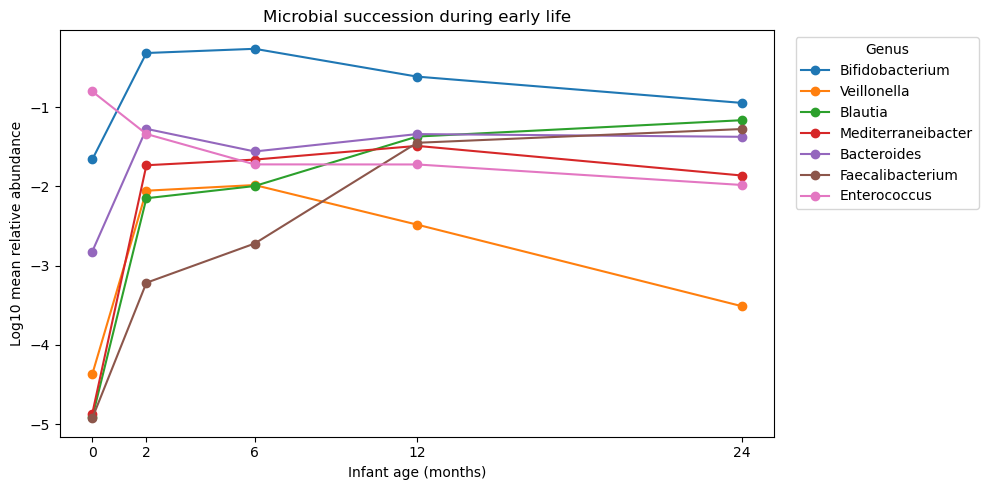

In [16]:
import numpy as np
import matplotlib.pyplot as plt

means = genus_abund.groupby(y).mean()

np.log10(means + 1e-5).plot(marker="o", figsize=(10, 5))

plt.xlabel("Infant age (months)")
plt.ylabel("Log10 mean relative abundance")
plt.title("Microbial succession during early life")
plt.xticks([0, 2, 6, 12, 24])
plt.legend(title="Genus", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(f"{output_dir}/microbial_succession.png", dpi=300, bbox_inches="tight")
plt.show